
**Objective:** develop a Generative Adversarial Network that generates realistic synthetic human faces from random noise.

> **Note:** the 30-epoch training (about 9 hours on a Kaggle T4) was run once in the notebook *Realistic face generation with GAN*.
> This notebook **does not retrain**. It loads the saved Generator and the samples saved during training, and presents the results:
> architecture, training curves, progress over time, final faces, interpolation and analysis.

**Before running:** add the output of the training notebook as input (**Add Input -> Your Work -> Notebooks -> Realistic face generation with GAN**, version 2).
Optional: also add the CelebA dataset (`jessicali9530/celeba-dataset`) for the real-vs-generated and FID cells.

## How a GAN works
A GAN is two networks playing a game:
- **Generator (G):** takes random noise `z` (a vector of 100 numbers) and turns it into a 64x64 face image.
- **Discriminator (D):** looks at an image and outputs the probability that it is a **real** CelebA face.

They are trained together (this pair of jointly trained models is the GAN):
1. D is trained on real faces (target 1) and on G's fake faces (target 0).
2. G is trained to make D output 1 for its fakes, so it learns to produce more realistic faces.

As D gets better at spotting fakes, G is forced to improve, and the faces become more realistic.

**Techniques used:** one-sided label smoothing (real label 0.9) so D does not become overconfident,
DCGAN-style weight initialization N(0, 0.02), Adam with beta1 = 0.5, and BatchNorm in both networks.

## 1. Setup

In [1]:
!pip install -q torch-fidelity torchmetrics

In [2]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
import torchvision.utils as vutils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NZ, NGF, NDF = 100, 64, 64
torch.manual_seed(42); np.random.seed(42)
print("Device:", device)

# Locate the files saved by the training notebook
gen_files  = glob.glob("/kaggle/input/**/generator.pth", recursive=True)
ckpt_files = glob.glob("/kaggle/input/**/gan_checkpoint.pt", recursive=True)
print("generator.pth:", gen_files)
print("gan_checkpoint.pt:", ckpt_files)
assert gen_files or ckpt_files, "Add the training notebook output (version 2) as Input"

ROOT = os.path.dirname((gen_files or ckpt_files)[0])
SAMPLES_DIR = os.path.join(ROOT, "samples")
print("Samples dir:", SAMPLES_DIR, "| images:", len(glob.glob(SAMPLES_DIR + "/*.png")))

Device: cuda
generator.pth: ['/kaggle/input/datasets/mairedaai/gan-face-results/generator.pth', '/kaggle/input/notebooks/mairedaai/realistic-face-generation-with-gan/generator.pth']
gan_checkpoint.pt: ['/kaggle/input/notebooks/mairedaai/realistic-face-generation-with-gan/gan_checkpoint.pt']
Samples dir: /kaggle/input/datasets/mairedaai/gan-face-results/samples | images: 30


## 2. Data and preprocessing
- **Dataset:** CelebA, 202,599 face images (`img_align_celeba`).
- **Center crop** 148x148 to focus on the face, **resize** to 64x64 (bicubic), **normalize** to [-1, 1] (matches the Generator's `tanh` output).
- Loaded with a `DataLoader` (batch size 128, shuffle, drop_last).

## 3. Models

In [3]:
class Generator(nn.Module):
    """Latent (100) -> 4x4x512 -> 8x8x256 -> 16x16x128 -> 32x32x64 -> 64x64x3 (tanh)."""
    def __init__(self, nz=NZ, ngf=NGF):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf*8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh(),
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    """64x64x3 -> 32 -> 16 -> 8 -> 4 -> probability real (sigmoid). No BatchNorm on the first layer."""
    def __init__(self, ndf=NDF):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False), nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x).view(-1)

netG, netD = Generator().to(device), Discriminator().to(device)
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"Generator parameters:     {count(netG):,}")
print(f"Discriminator parameters: {count(netD):,}")

# Load the trained Generator
if gen_files:
    netG.load_state_dict(torch.load(gen_files[0], map_location=device))
    print("Loaded generator.pth")
else:
    ck = torch.load(ckpt_files[0], map_location=device)
    netG.load_state_dict(ck["G"]); print("Loaded checkpoint, epoch", ck["epoch"])
netG.eval()

Generator parameters:     3,576,704
Discriminator parameters: 2,765,568
Loaded generator.pth


Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)

## 4. Training setup
| Setting | Value |
|---|---|
| Loss | Binary cross-entropy |
| Optimizer | Adam, lr 2e-4, beta1 0.5 (both networks) |
| Batch size / epochs | 128 / 30 |
| Latent size | 100 |
| Label smoothing | real = 0.9, fake = 0 |
| Hardware / time | Kaggle GPU T4, about 550 minutes |

### Combining G and D into a GAN
Both models are trained jointly inside one loop. For every batch:
1. Sample random latent vectors `z ~ N(0, 1)` and generate fake faces with G.
2. Update D using real faces and `fake.detach()`.
3. Update G using the same fakes, with labels flipped to "real", so gradients flow through D into G.

A fixed noise batch (64 vectors) was used to save a grid of generated faces after every epoch.

## 5. Training curves (values from the training log, 30 epochs)

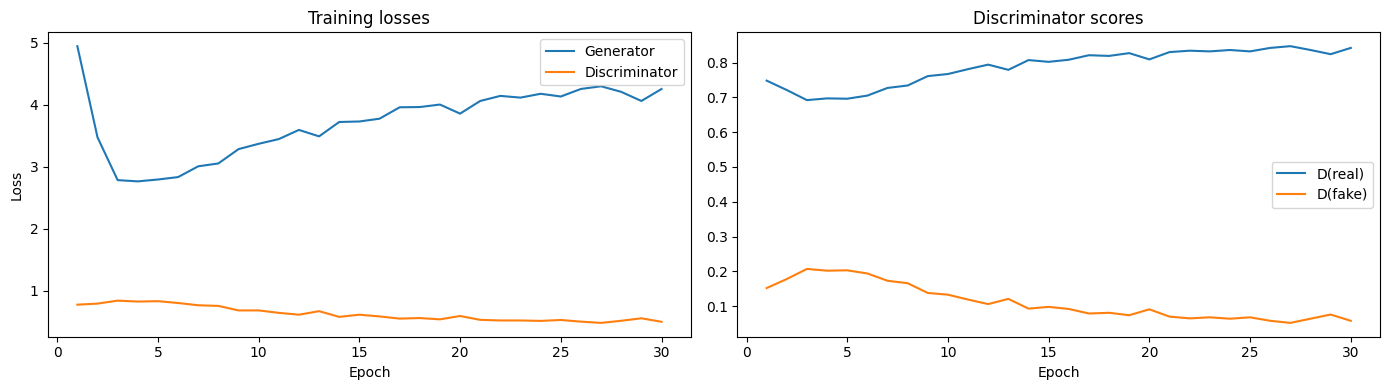

In [4]:
D_losses = [0.777,0.794,0.842,0.827,0.833,0.804,0.767,0.757,0.684,0.684,0.645,0.615,0.672,0.580,0.615,
            0.587,0.552,0.561,0.540,0.594,0.532,0.522,0.522,0.515,0.530,0.503,0.483,0.517,0.557,0.501]
G_losses = [4.947,3.477,2.786,2.766,2.796,2.835,3.009,3.055,3.286,3.372,3.448,3.596,3.492,3.724,3.732,
            3.777,3.961,3.965,4.005,3.859,4.063,4.145,4.117,4.179,4.135,4.257,4.300,4.210,4.063,4.256]
D_real   = [0.748,0.721,0.692,0.697,0.696,0.705,0.727,0.734,0.761,0.767,0.781,0.794,0.779,0.807,0.802,
            0.808,0.821,0.819,0.827,0.809,0.830,0.834,0.832,0.836,0.832,0.842,0.847,0.836,0.824,0.842]
D_fake   = [0.152,0.178,0.207,0.202,0.203,0.194,0.173,0.166,0.138,0.133,0.119,0.106,0.121,0.093,0.098,
            0.092,0.079,0.081,0.074,0.091,0.070,0.065,0.068,0.064,0.068,0.058,0.052,0.064,0.076,0.058]
assert len(D_losses) == len(G_losses) == len(D_real) == len(D_fake) == 30
ep = range(1, 31)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ep, G_losses, label="Generator"); ax[0].plot(ep, D_losses, label="Discriminator")
ax[0].set_title("Training losses"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
ax[1].plot(ep, D_real, label="D(real)"); ax[1].plot(ep, D_fake, label="D(fake)")
ax[1].set_title("Discriminator scores"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

## 6. Progress over time (same fixed noise at different epochs)

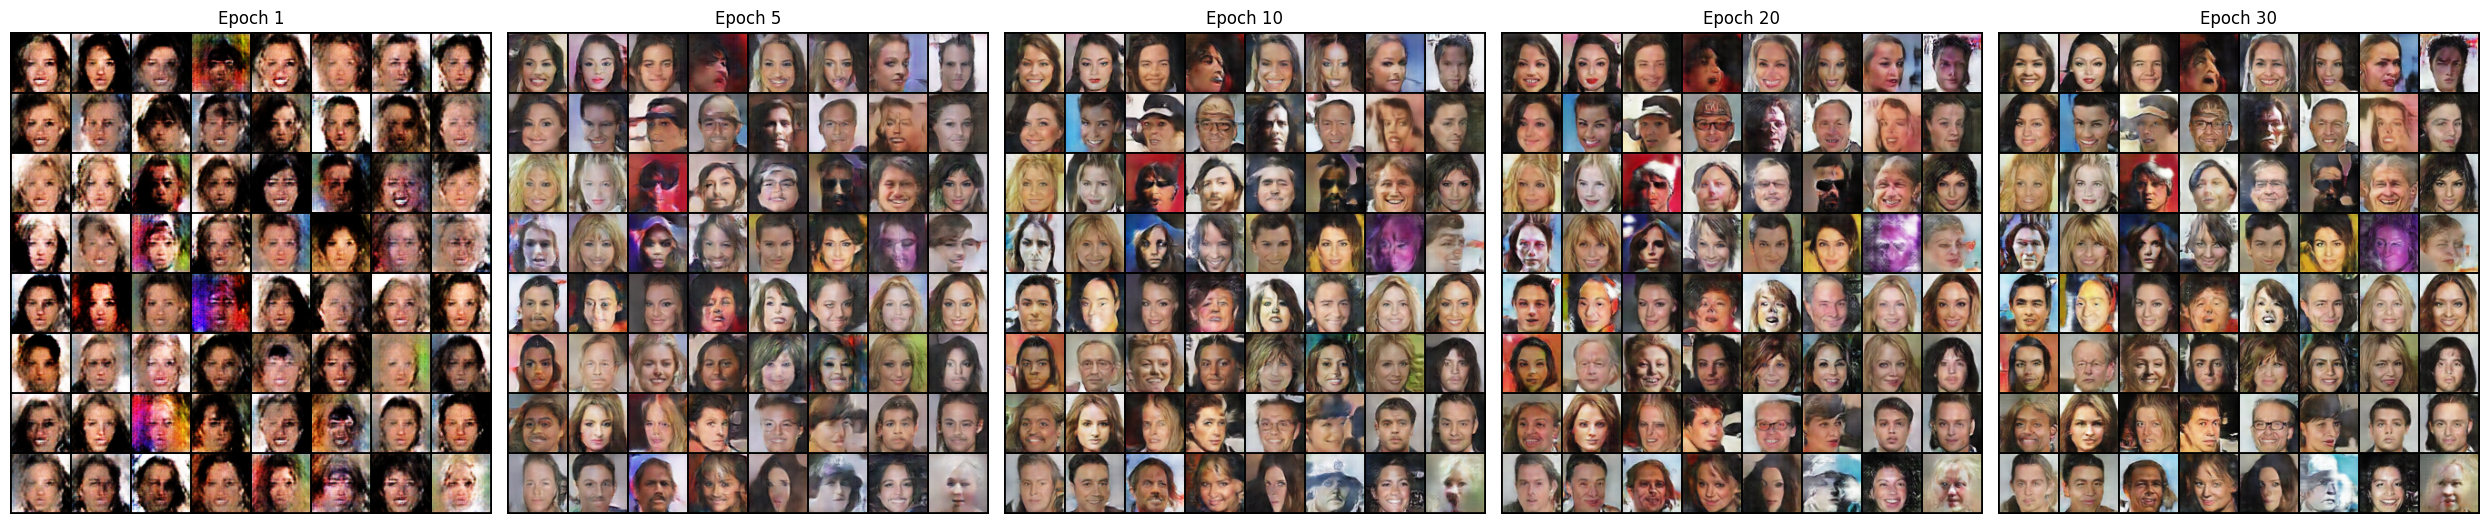

Saved training_progress.gif with 30 frames


In [5]:
show = [1, 5, 10, 20, 30]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 5.5))
for ax, e in zip(axes, show):
    ax.imshow(Image.open(f"{SAMPLES_DIR}/epoch_{e:03d}.png")); ax.set_title(f"Epoch {e}"); ax.axis("off")
plt.tight_layout(); plt.savefig("progress_comparison.png", dpi=150); plt.show()

files = sorted(glob.glob(SAMPLES_DIR + "/epoch_*.png"))
frames = [Image.open(f) for f in files]
frames[0].save("training_progress.gif", save_all=True, append_images=frames[1:], duration=300, loop=0)
print("Saved training_progress.gif with", len(frames), "frames")

## 7. Final generated faces (new random noise)

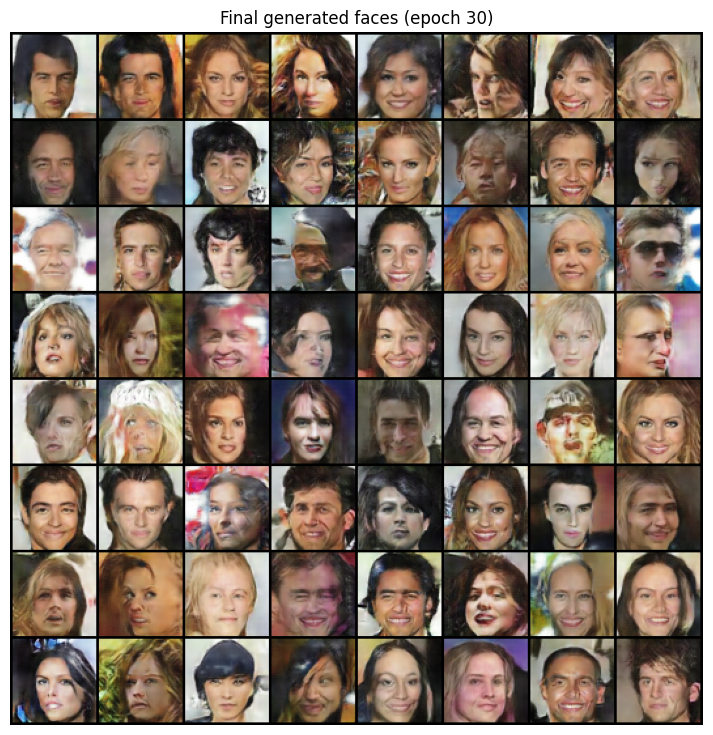

In [6]:
with torch.no_grad():
    final = netG(torch.randn(64, NZ, 1, 1, device=device)).cpu()
plt.figure(figsize=(9, 9)); plt.axis("off"); plt.title("Final generated faces (epoch 30)")
plt.imshow(vutils.make_grid(final, nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.savefig("final_faces.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Real vs generated (needs CelebA added as input)

CelebA images found: 202599


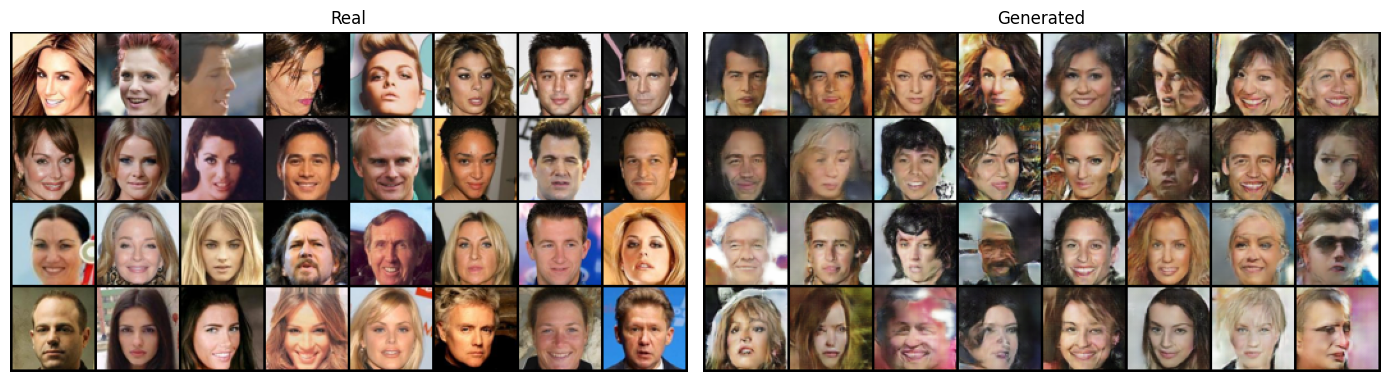

In [7]:
import torchvision.transforms as T
tf = T.Compose([T.CenterCrop(148), T.Resize(64, interpolation=T.InterpolationMode.BICUBIC),
                T.ToTensor(), T.Normalize((0.5,)*3, (0.5,)*3)])
paths = glob.glob("/kaggle/input/**/img_align_celeba/**/*.jpg", recursive=True)
celeba = sorted({os.path.basename(p): p for p in paths}.values())   # remove duplicates
print("CelebA images found:", len(celeba))
if celeba:
    real = torch.stack([tf(Image.open(p).convert("RGB")) for p in celeba[:32]])
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    ax[0].imshow(vutils.make_grid(real, nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); ax[0].set_title("Real"); ax[0].axis("off")
    ax[1].imshow(vutils.make_grid(final[:32], nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); ax[1].set_title("Generated"); ax[1].axis("off")
    plt.tight_layout(); plt.savefig("real_vs_generated.png", dpi=150); plt.show()
else:
    print("Skipped: add the CelebA dataset as input to see this comparison.")

## 9. Latent space interpolation

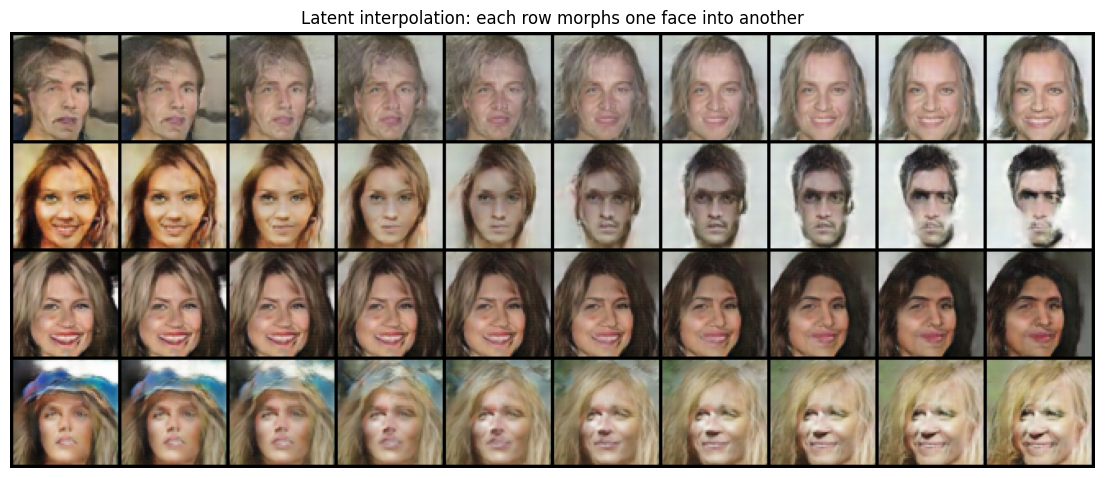

In [8]:
def interpolate(steps=10):
    z1, z2 = torch.randn(1, NZ, 1, 1, device=device), torch.randn(1, NZ, 1, 1, device=device)
    a = torch.linspace(0, 1, steps, device=device).view(-1, 1, 1, 1)
    with torch.no_grad():
        return netG((1 - a) * z1 + a * z2).cpu()

rows = torch.cat([interpolate() for _ in range(4)])
plt.figure(figsize=(14, 6)); plt.axis("off"); plt.title("Latent interpolation: each row morphs one face into another")
plt.imshow(vutils.make_grid(rows, nrow=10, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.savefig("interpolation.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. (Optional) FID score
Lower FID is better. This uses 5,000 real and 5,000 generated images, which gives a higher (biased) value than the standard 50k-sample FID,
so report it as **"FID (5k samples)"**. Needs the CelebA input, and **Internet On** in the notebook settings (to download the Inception weights).

In [9]:
# !pip install -q torchmetrics torch-fidelity
try:
    from torchmetrics.image.fid import FrechetInceptionDistance
    assert celeba, "CelebA input not found"
    N_EVAL = 5000
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)   # inputs: floats in [0, 1]
    for i in range(0, N_EVAL, 100):
        batch = torch.stack([tf(Image.open(p).convert("RGB")) for p in celeba[i:i+100]]).to(device)
        fid.update((batch * 0.5 + 0.5).clamp(0, 1), real=True)
    with torch.no_grad():
        for _ in range(N_EVAL // 100):
            fake = netG(torch.randn(100, NZ, 1, 1, device=device))
            fid.update((fake * 0.5 + 0.5).clamp(0, 1), real=False)
    print(f"FID (5k samples): {fid.compute().item():.2f}")
except Exception as e:
    print("FID skipped:", e)

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 626MB/s]


FID (5k samples): 28.85


## 11. Analysis and conclusions
- **Training stability:** no mode collapse; final D loss 0.50, G loss 4.26, D(real) 0.84, D(fake) 0.06.
- **Progress:** blurry color noise at epoch 1, clear and diverse faces from epoch 5, finer details (hair, glasses, backgrounds) through epoch 30. Most of the gain happened in the first 10 epochs.
- **Discriminator vs Generator:** D slowly became stronger (D(fake) fell from about 0.2 to 0.06), which is consistent with the artifacts that remain in some generated faces.
- **Losses are not a quality metric:** the saved images, not the curves, showed how good the model was.
- **Limitations:** 64x64 resolution, some distorted faces, CelebA demographic bias.
- **Next steps:** WGAN-GP or spectral normalization, higher resolution (128x128), longer training, conditional generation (e.g., by attribute).

## 12. Save the Generator

In [10]:
torch.save(netG.state_dict(), "generator_final.pth")
print("Saved generator_final.pth")

Saved generator_final.pth
